# AML Lab Exam - Cheat Notebook
Every model follows the **same 5 lines**:
```
X, y  ->  split  ->  fit  ->  predict  ->  score
```
In the exam, replace the practice data with your CSV:
```python
df = pd.read_csv("yourfile.csv")
X = df[["col1", "col2"]]     # inputs (double brackets!)
y = df["target"]             # output
```

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 0. Preprocessing (clean the data first)
1. `head()`, `info()`, `isnull().sum()`  
2. fill missing values  
3. text columns -> numbers (`get_dummies`)  
4. split, then scale (fit on train only)

In [ ]:
df = pd.DataFrame({
    "Country": ["France", "Spain", "Germany", "Spain", "Germany", "France", "Spain", "France", "Germany", "France"],
    "Age": [44, 27, 30, 38, 40, 35, None, 48, 50, 37],
    "Salary": [72000, 48000, 54000, 61000, None, 58000, 52000, 79000, 83000, 67000],
    "Purchased": ["No", "Yes", "No", "No", "Yes", "Yes", "No", "Yes", "No", "Yes"],
})
# df = pd.read_csv("Data.csv")

print(df.head())
print(df.isnull().sum())

   Country   Age   Salary Purchased
0   France  44.0  72000.0        No
1    Spain  27.0  48000.0       Yes
2  Germany  30.0  54000.0        No
3    Spain  38.0  61000.0        No
4  Germany  40.0      NaN       Yes
Country      0
Age          1
Salary       1
Purchased    0
dtype: int64


In [ ]:
# fill missing numbers with the mean
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())

# text -> numbers
df["Purchased"] = df["Purchased"].map({"No": 0, "Yes": 1})
df = pd.get_dummies(df, columns=["Country"], drop_first=True, dtype=int)
print(df)

         Age        Salary  Purchased  Country_Germany  Country_Spain
0  44.000000  72000.000000          0                0              0
1  27.000000  48000.000000          1                0              1
2  30.000000  54000.000000          0                1              0
3  38.000000  61000.000000          0                0              1
4  40.000000  63777.777778          1                1              0
5  35.000000  58000.000000          1                0              0
6  38.777778  52000.000000          0                0              1
7  48.000000  79000.000000          1                0              0
8  50.000000  83000.000000          0                1              0
9  37.000000  67000.000000          1                0              0


In [ ]:
X = df.drop("Purchased", axis=1)
y = df["Purchased"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)   # fit on train
X_test = sc.transform(X_test)         # only transform test
print(X_train)

[[ 0.26306757  0.12381479  2.64575131 -0.77459667]
 [-0.25350148  0.46175632 -0.37796447 -0.77459667]
 [-1.97539832 -1.53093341 -0.37796447  1.29099445]
 [ 0.05261351 -1.11141978 -0.37796447  1.29099445]
 [ 1.64058505  1.7202972  -0.37796447 -0.77459667]
 [-0.0813118  -0.16751412 -0.37796447  1.29099445]
 [ 0.95182631  0.98614835 -0.37796447 -0.77459667]
 [-0.59788085 -0.48214934 -0.37796447 -0.77459667]]


## 1. Simple Linear Regression
`y = b0 + b1*x`  -  metrics: MAE, MSE, RMSE, R² (closer to 1 = better)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.DataFrame({"Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                   "Marks": [32, 38, 43, 50, 54, 61, 68, 73, 81, 88]})
# df = pd.read_csv("Salary_Data.csv")

X = df[["Hours"]]     # 2D
y = df["Marks"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Intercept b0:", model.intercept_)
print("Slope b1:", model.coef_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

Intercept b0: 25.18199608610567
Slope b1: [6.10567515]
MAE: 0.6829745596868904
MSE: 0.5002929676280378
RMSE: 0.7073139102463897
R2: 0.9986141469040775


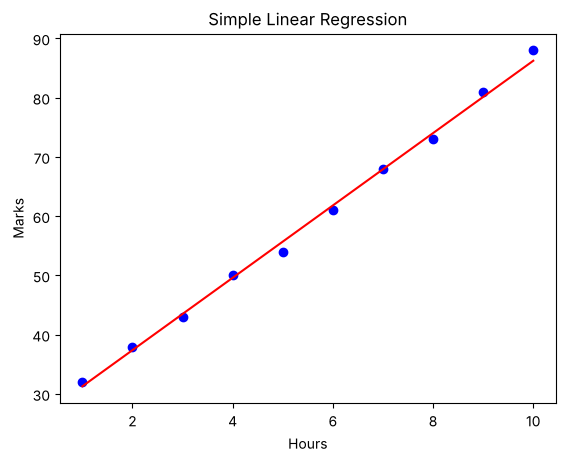

Prediction for 6.5 hours: [64.86888454]


In [ ]:
plt.scatter(X, y, color="blue")
plt.plot(X, model.predict(X), color="red")
plt.xlabel("Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.show()

print("Prediction for 6.5 hours:", model.predict(pd.DataFrame({"Hours": [6.5]})))

## 2. Multiple Linear Regression
Same code, just more columns in X.

In [ ]:
df = pd.DataFrame({
    "Hours":      [2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    "Attendance": [60, 65, 70, 72, 80, 85, 88, 90, 95, 97],
    "Marks":      [50, 55, 60, 63, 70, 76, 80, 85, 91, 95],
})

X = df[["Hours", "Attendance"]]
y = df["Marks"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("R2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

Intercept: 25.318249875228737
Coefficients: [3.91099651 0.27000499]
R2: 0.9981941797287442
RMSE: 0.6586716330381955


## 3. Logistic Regression (classification)
Output = probability (sigmoid), class = 1 if p ≥ 0.5  
Metrics: accuracy, confusion matrix, precision, recall, F1, ROC-AUC

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

data = load_breast_cancer()
X = data.data
y = data.target
# df = pd.read_csv("Social_Network_Ads.csv")
# X = df[["Age", "EstimatedSalary"]]
# y = df["Purchased"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.958041958041958
Confusion matrix:
 [[50  3]
 [ 3 87]]
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        53
           1       0.97      0.97      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.96      0.96       143
weighted avg       0.96      0.96      0.96       143



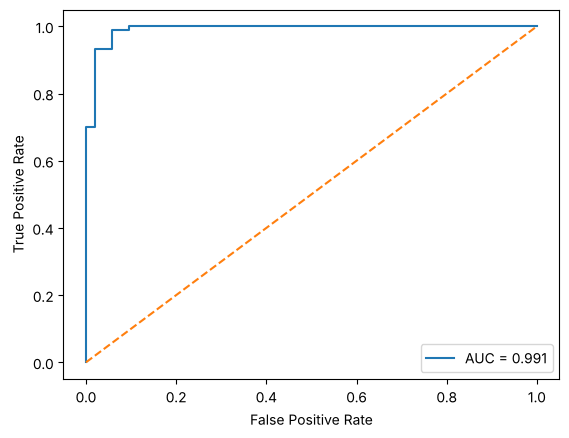

In [ ]:
# ROC curve
y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label="AUC = " + str(round(roc_auc_score(y_test, y_prob), 3)))
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 4. ANOVA
**H0:** all group means are equal. **p < 0.05 → reject H0** (means differ).  
F = variance between groups / variance within groups.

In [ ]:
from scipy import stats
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data, columns=["sepal_length", "sepal_width", "petal_length", "petal_width"])
df["species"] = iris.target
# df = pd.read_csv("yourfile.csv")

g0 = df[df["species"] == 0]["petal_length"]
g1 = df[df["species"] == 1]["petal_length"]
g2 = df[df["species"] == 2]["petal_length"]

f, p = stats.f_oneway(g0, g1, g2)
print("F =", f)
print("p =", p)

if p < 0.05:
    print("Reject H0: group means are different")
else:
    print("Accept H0: no significant difference")

F = 1180.161182252976
p = 2.856776610962404e-91
Reject H0: group means are different


In [ ]:
# ANOVA table with statsmodels
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols("petal_length ~ C(species)", data=df).fit()
print(sm.stats.anova_lm(model, typ=2))

              sum_sq     df            F        PR(>F)
C(species)  437.1028    2.0  1180.161182  2.856777e-91
Residual     27.2226  147.0          NaN           NaN


In [ ]:
# ANOVA for feature selection (picks the best features)
from sklearn.feature_selection import SelectKBest, f_classif

X = df.drop("species", axis=1)
y = df["species"]

selector = SelectKBest(f_classif, k=2)
selector.fit(X, y)
print("F-scores:", selector.scores_)
print("Selected:", X.columns[selector.get_support()])

F-scores: [ 119.26450218   49.16004009 1180.16118225  960.0071468 ]
Selected: Index(['petal_length', 'petal_width'], dtype='str')


## 5. Decision Tree
`criterion="entropy"` (information gain) or `"gini"`. Use `max_depth` to stop overfitting.

Accuracy: 0.9736842105263158
[[13  0  0]
 [ 0 15  1]
 [ 0  0  9]]


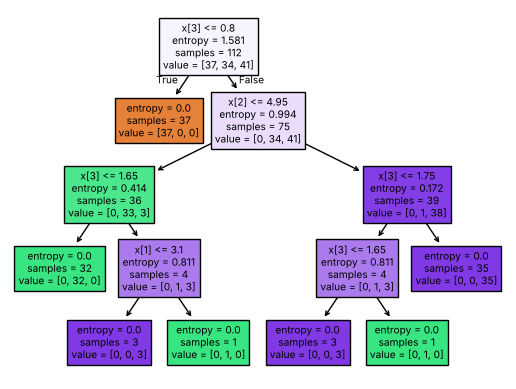

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

model = DecisionTreeClassifier(criterion="entropy", random_state=0)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

plot_tree(model, filled=True)
plt.show()

## 6. KNN and Naive Bayes (same pattern)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

for model in [KNeighborsClassifier(n_neighbors=5), GaussianNB()]:
    model.fit(X_train, y_train)
    print(model, "accuracy:", accuracy_score(y_test, model.predict(X_test)))

KNeighborsClassifier() accuracy: 0.9736842105263158
GaussianNB() accuracy: 1.0


## 7. Ridge and Lasso
Ridge (L2) shrinks coefficients. Lasso (L1) can make them 0 (removes features). Bigger alpha = stronger penalty.

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge, Lasso, RidgeCV, LassoCV

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

for model in [LinearRegression(), Ridge(alpha=1.0), Lasso(alpha=0.1)]:
    model.fit(X_train, y_train)
    print(model, "R2:", round(r2_score(y_test, model.predict(X_test)), 3))

# best alpha
ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]).fit(X_train, y_train)
lasso = LassoCV(alphas=[0.01, 0.1, 1, 10, 100]).fit(X_train, y_train)
print("Best Ridge alpha:", ridge.alpha_)
print("Best Lasso alpha:", lasso.alpha_)
print("Lasso coefficients:", lasso.coef_.round(1))

LinearRegression() R2: 0.332
Ridge() R2: 0.341
Lasso(alpha=0.1) R2: 0.34
Best Ridge alpha: 0.01
Best Lasso alpha: 0.01
Lasso coefficients: [ -25.7 -233.   569.5  294.4 -250.3    0.  -157.2  109.   577.9   41.2]


## 8. Feature Selection
Chi-square needs non-negative values → MinMaxScaler first.

In [ ]:
from sklearn.feature_selection import chi2, RFE, VarianceThreshold
from sklearn.preprocessing import MinMaxScaler

data = load_breast_cancer()
X = data.data
y = data.target

# Variance threshold: drops columns that barely change
print("Variance threshold keeps:", VarianceThreshold(0.1).fit_transform(X).shape[1], "columns")

# Chi-square
X_pos = MinMaxScaler().fit_transform(X)
chi = SelectKBest(chi2, k=5).fit(X_pos, y)
print("Chi2 best:", data.feature_names[chi.get_support()])

# RFE (removes the weakest feature one by one)
rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=5).fit(StandardScaler().fit_transform(X), y)
print("RFE best:", data.feature_names[rfe.support_])

Variance threshold keeps: 11 columns
Chi2 best: ['mean concavity' 'mean concave points' 'worst perimeter' 'worst area'
 'worst concave points']
RFE best: ['radius error' 'worst radius' 'worst texture' 'worst area'
 'worst concave points']


## 9. Cross-validation and overfitting
Underfit = train & test error both high. Overfit = train low, test high.

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(LogisticRegression(max_iter=5000), X, y, cv=5)
print("5-fold accuracy:", scores)
print("Mean:", scores.mean())

5-fold accuracy: [0.93859649 0.94736842 0.98245614 0.92982456 0.95575221]
Mean: 0.9507995652848935


## Quick formulas
| | |
|---|---|
| Accuracy | (TP+TN) / total |
| Precision | TP / (TP+FP) |
| Recall | TP / (TP+FN) |
| F1 | 2·P·R / (P+R) |
| MSE | mean((y − ŷ)²) |
| R² | 1 − SS_res / SS_tot |

**Common errors:** `Expected 2D array` → use `df[["col"]]` · `could not convert string to float` → `get_dummies` / `map` · `Input contains NaN` → `fillna`